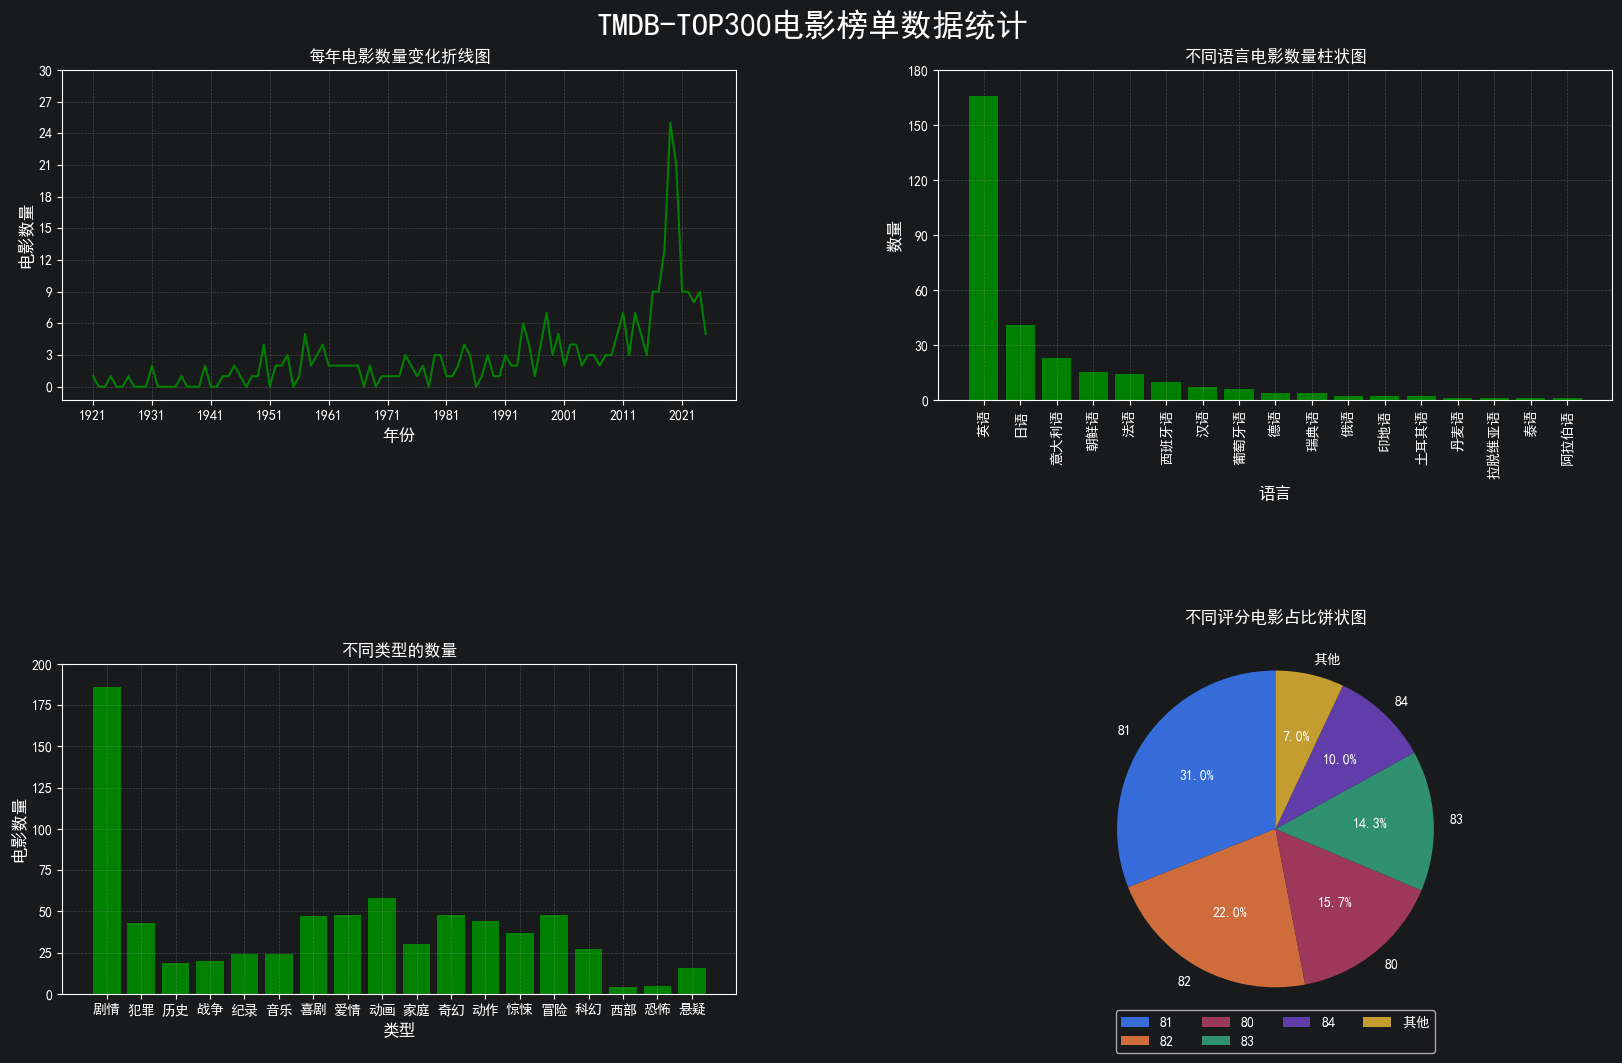

In [22]:
from matplotlib.axes import Axes
import matplotlib.pyplot as plt
import pandas as pd

# 展示中文
plt.rcParams['font.sans-serif'] = ['SimHei']

# 创建子图
fig,axes = plt.subplots(nrows=2,ncols=2,figsize=(20,12),dpi=100) # 解包操作
fig.suptitle('TMDB-TOP300电影榜单数据统计',fontsize=23,x=0.5,y=0.93) # 添加画布标签 - x=0.5 : x轴位置,y=0.95 : y轴位置
fig.subplots_adjust(hspace=0.8,wspace=0.3)

# 获取子图
axes1:Axes = axes[0,0] # 第一个子图
axes2:Axes = axes[0,1] # 第二个子图
axes3:Axes = axes[1,0] # 第三个子图
axes4:Axes = axes[1,1] # 第四个子图

# 加载数据
# int64 : 整型数字（不支持空值）
# Int64 : 整型数字（支持空值）
# float64 : 浮点型数字（支持空值）

df = pd.read_csv('data/movies.csv',usecols=['电影名','年份','上映时间','类型','时长','评分','语言'],dtype={'年份':'Int64'})

# 1.需求一：统计TOP300的电影中，每一年上映的电影数量的变化。（折线图）
# 1.1 缺失值、异常值的处理
df['年份'] = df['年份'].fillna(df['上映时间'].str[:4])
# df.isnull().sum()

# 1.2 分组统计
year_count = df.groupby('年份')['年份'].count()

# 1.3 组装数据
# x轴数据
min_year = year_count.index.min()
max_year = year_count.index.max()
x = [i for i in range(min_year,max_year+1)]

# y轴数据
y =[int(year_count.get(i,0)) for i in x] # 得到key = i，就填充value，否则填充0

# 1.4 绘制折线图
axes1.plot(x,y,color='g') # 绘制折线图
axes1.set_title('每年电影数量变化折线图') # 添加子图标题
axes1.set_xlabel('年份',fontsize=12) # 添加x轴标签
axes1.set_ylabel('电影数量',fontsize=12) # 添加y轴标签

axes1.set_xticks(x[::10]) # 设置x轴刻度
y_ticks = [i for i in range(0,31,3)]
axes1.set_yticks(y_ticks) # 设置y轴刻度
axes1.grid(linestyle='--',alpha=0.3)


# 2.需求二: 统计对比不同语言的电影数量。（柱状图）
# 2.1 统计不同语言对应的电影数量
language_count = df.groupby('语言')['语言'].count().sort_values(ascending=False)

x_language = language_count.index.tolist()
y_language_count = language_count.values.tolist()

# 2.2 绘制柱状图
axes2.bar(x_language,y_language_count,color='g') # 柱状图
axes2.set_title('不同语言电影数量柱状图') # 添加子图标题
axes2.set_xlabel('语言',fontsize=12) # 添加x轴标签
axes2.set_ylabel('数量',fontsize=12) # 添加y轴标签

y_ticks = [i for i in range(0,181,30)] # y轴刻度
axes2.set_yticks(y_ticks) # 设置y轴刻度
axes2.grid(linestyle='--',alpha=0.3) # 添加网格
axes2.tick_params(axis='x',rotation=90) # x轴标签旋转90度


# 3.需求三: 统计对比不同类型电影数量
# 3.1 统计不同类型电影数量
type_count = {}
for types in df['类型'].str.split(","):
    for type in types:
        if type in type_count:
            type_count[type] += 1
        else:
            type_count[type] = 1

x = list(type_count.keys())
y = list(type_count.values())

# 3.2 绘制柱状图
axes3.bar(x,y,color='g')
axes3.set_title('不同类型的数量') # 添加子图标题
axes3.set_xlabel('类型',fontsize=12) # 添加x轴标签
axes3.set_ylabel('电影数量',fontsize=12) # 添加y轴标签
y_ticks = [i for i in range(0,201,25)]
axes3.set_yticks(y_ticks)
axes3.grid(linestyle='--',alpha=0.3)


# 4. 需求四: 统计对比各个评分的电影占比
# 4.1 统计各个评分的数量
score_count = df.groupby('评分')['评分'].count().sort_values(ascending=False)

# 合并小数据（比例小于%6）--> 其他
total = score_count.sum()
large_scores = score_count.loc[score_count >= total*0.06] # 大数据，比例大于%6
small_scores = score_count.loc[score_count < total*0.06] # 小数据，比例小于%6
if small_scores.shape[0] > 0:
    large_scores['其他'] = small_scores.sum()


scores = large_scores.index.tolist()
scores_values = large_scores.values.tolist()

# 4.2 绘制饼状图
axes4.pie(scores_values,labels=scores,autopct='%1.1f%%',startangle=90,radius=1.2) # startangle为起始角度
axes4.set_title('不同评分电影占比饼状图',fontsize=12,y=1.1)
axes4.legend(loc='lower center',ncol=4,bbox_to_anchor=(0.5,-0.2))

# 5.保存图片
plt.savefig('data/TMDB-TOP300.png')


plt.show() # 展示画布